# AOD experiment: Python → C → RISC-V → X/Y waveforms

This notebook runs **without an FPGA board or Vivado**. Verilator simulates the actual
`AodSoc` RTL: the RISC-V CPU executes our compiled experiment and sends posted writes
to the timed AOD engine. Cocotb supplies clocks and host AXI transactions and captures
native output samples. There is no Python replacement for the CPU or waveform generator.

We will load trajectory/envelope/gain tables once, compile an experiment, inspect
its generated C and RISC-V instructions, run three paired frequency sweeps, and
rerun with a new initial phase while keeping the tables and firmware loaded.

The interactive build uses two tones per axis (one enabled), the production 6,250-step
profile geometry, a two-entry pending queue, and a 400 MHz DSP clock. The default
hardware build has 32 tones per axis. This demonstrates digital waveforms, **not atom
motion or RF hardware behavior**. Output is zero between jobs: other confinement or
an explicit transfer protocol is required during those intervals.

From the repository root, after putting the RISC-V LLVM toolchain on `PATH`:

```sh
uv sync --project software --extra notebook --locked
uv run --project software --extra notebook --locked jupyter lab examples/aod_moves.ipynb
```

See [the setup and workflow guide](../docs/software/aod.md) for native tool requirements,
headless execution, the supported kernel subset and cleanup. The first simulation build
can take a few minutes; subsequent runs reuse its checked source/toolchain cache.

In [1]:
from pathlib import Path
import inspect
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Code, display

import riscq
from riscq.lang import Array, kernel
from riscq.aod import (AodMap, AodSession, compile_kernel, read_profile,
                       aod_init, aod_rate, aod_axis, aod_tone, aod_fire_at,
                       aod_start_spacing, now, wait_until)
from riscq.sim import aod as simulator

# Python dependencies are locked; these native tools must already be on PATH.
for tool, location in simulator.preflight().items():
    print(f"{tool:34} {location}")
ROOT = Path(riscq.__file__).resolve().parents[2]

java                               /usr/bin/java
verilator                          /usr/bin/verilator
make                               /usr/bin/make
g++                                /usr/bin/g++
riscv64-unknown-elf-clang          /home/ethan/.local/opt/riscv-llvm-2025.01.20/bin/riscv64-unknown-elf-clang
riscv64-unknown-elf-objcopy        /home/ethan/.local/opt/riscv-llvm-2025.01.20/bin/riscv64-unknown-elf-objcopy
riscv64-unknown-elf-nm             /home/ethan/.local/opt/riscv-llvm-2025.01.20/bin/riscv64-unknown-elf-nm
riscv64-unknown-elf-objdump        /home/ethan/.local/opt/riscv-llvm-2025.01.20/bin/riscv64-unknown-elf-objdump
cocotb                             1.8.1
numpy                              2.5.4
Pyro5                              5.17
python                             /home/ethan/research/riscq-aod/RISC-Q/software/.venv/bin/python


## 1. Start the simulated SoC

The host interface behaves like a board's memory-mapped AXI aperture, but is local
to this computer. The CPU powers up held in reset. Shared DSP time free-runs across
shots. The build supplies its own manifest so code generation uses the actual
hardware geometry and memory map.

In [2]:
# Stop a previous instance if this cell is rerun interactively.
if "driver" in globals():
    simulator.stop(driver)
driver = simulator.start()
mapping = AodMap(__import__("json").loads(driver.sim.get_params()))
session = AodSession(driver, mapping)
print({key: mapping.manifest[key] for key in
       ("axes", "tones", "move_steps", "queue_depth", "dsp_hz")})

{'axes': 2, 'tones': 2, 'move_steps': 6250, 'queue_depth': 2, 'dsp_hz': 400000000}


## 2. Write the on-core experiment in Python

Only the marked `@kernel` function is compiled. This is RISC-Q's typed integer
Python subset: bounded/unbounded loops, conditionals, integer arithmetic, named
runtime parameters and result arrays. Host NumPy, plotting and table setup stay
in Python on this computer.

Intrinsics such as `aod_tone` and `aod_fire_at` become calls to the AOD C header.
They initialize all tone state, stage the next movement, atomically enqueue the
paired X/Y parameters with a start timestamp, and pace the finite queue with the
existing time-comparator wait. The next movement is staged while the current one
is active; each movement has its own initial phase. No memory addresses appear
in the experiment function.

In [3]:
N = 3
RATE = 8
LEAD = 8192           # generous CPU/fabric/link + AOD preparation margin, in DSP clocks
GAP = 4096           # extra RF-off clocks beyond conservative start spacing

@kernel
def moves(starts: Array, n: int, fx: int, dx: int, fy: int, dy: int,
          amplitude: int, phase: int):
    aod_init()       # initialize every field, including disabled tones
    aod_rate(RATE, 1)
    aod_axis(0, 1, 0, amplitude)  # enable tone 0 only
    aod_axis(1, 1, 0, amplitude)
    t = now() + LEAD
    for i in range(n):
        if i % 2 == 0:
            aod_tone(0, 0, fx, dx, phase, 32768, 32768)
            aod_tone(1, 0, fy, dy, phase, 32768, 32768)
        else:
            aod_tone(0, 0, fx + dx, 0 - dx, phase, 32768, 32768)
            aod_tone(1, 0, fy + dy, 0 - dy, phase, 32768, 32768)
        starts[i] = t
        aod_fire_at(t)
        wait_until(t + 16)
        t = t + aod_start_spacing(RATE) + GAP
    wait_until(t)    # let the final waveform and snapshot drain before returning

program = compile_kernel(moves, mapping, n=N, starts=Array(N))
display(Code(inspect.getsource(moves.fn), language="python"))

@kernel
def moves(starts: Array, n: int, fx: int, dx: int, fy: int, dy: int,
          amplitude: int, phase: int):
    aod_init()       # initialize every field, including disabled tones
    aod_rate(RATE, 1)
    aod_axis(0, 1, 0, amplitude)  # enable tone 0 only
    aod_axis(1, 1, 0, amplitude)
    t = now() + LEAD
    for i in range(n):
        if i % 2 == 0:
            aod_tone(0, 0, fx, dx, phase, 32768, 32768)
            aod_tone(1, 0, fy, dy, phase, 32768, 32768)
        else:
            aod_tone(0, 0, fx + dx, 0 - dx, phase, 32768, 32768)
            aod_tone(1, 0, fy + dy, 0 - dy, phase, 32768, 32768)
        starts[i] = t
        aod_fire_at(t)
        wait_until(t + 16)
        t = t + aod_start_spacing(RATE) + GAP
    wait_until(t)    # let the final waveform and snapshot drain before returning

## 3. Inspect the generated C

The shared frontend resolves constants and validates control flow, then emits
ordinary freestanding C. Runtime parameters are `.data` globals: the host can
change them before a shot without recompiling. The result array lives in RAM.
[`riscq_aod.h`](../software/fw/riscq_aod.h) translates AOD operations into the memory-mapped stores; shared
startup initializes the CPU stack/BSS and publishes DONE when `main` returns.

In [4]:
display(Code(program.c_source, language="c"))

/* GENERATED by riscq.lang from @kernel 'moves' (/tmp/ipykernel_678653/3546125686.py:7) — do not edit. */
#include "riscq_aod.h"

/* runtime parameters — host-written by name; RQ_PARAM pins them into .data */
volatile int32_t RQ_PARAM fx = 0;
volatile int32_t RQ_PARAM dx = 0;
volatile int32_t RQ_PARAM fy = 0;
volatile int32_t RQ_PARAM dy = 0;
volatile int32_t RQ_PARAM amplitude = 0;
volatile int32_t RQ_PARAM phase = 0;
/* result arrays (.bss) — host-read by name */
volatile int32_t starts[3];

int main(void) {
    int32_t t;
    int32_t i;

#line 9 "/tmp/ipykernel_678653/3546125686.py"
    aod_init();
#line 10 "/tmp/ipykernel_678653/3546125686.py"
    aod_rate(8, 1);
#line 11 "/tmp/ipykernel_678653/3546125686.py"
    aod_axis(0, 1, 0, amplitude);
#line 12 "/tmp/ipykernel_678653/3546125686.py"
    aod_axis(1, 1, 0, amplitude);
#line 13 "/tmp/ipykernel_678653/3546125686.py"
    t = now() + 8192;
#line 14 "/tmp/ipykernel_678653/3546125686.py"
    for (i = 0; i < 3; i += 1) {
#line 15 "/tmp/ipykernel_678653/3546125686.py"
        if (i % 2 == 0) {
#line 16 "/tmp/ipykernel_678653/3546125686.py"
            aod_tone(0, 0, fx, dx, phase, 32768, 32768);
#line 17 "/tmp/ipykernel_678653/3546125686.py"
            aod_tone(1, 0, fy, dy, phase, 32768, 32768);
        } else {
#line 19 "/tmp/ipykernel_678653/3546125686.py"
            aod_tone(0, 0, fx + dx, 0 - dx, phase, 32768, 32768);
#line 20 "/tmp/ipykernel_678653/3546125686.py"
            aod_tone(1, 0, fy + dy, 0 - dy, phase, 32768, 32768);
        }
#line 21 "/tmp/ipykernel_678653/3546125686.py"
        starts[i] = t;
#line 22 "/tmp/ipykernel_678653/3546125686.py"
        aod_fire_at(t);
#line 23 "/tmp/ipykernel_678653/3546125686.py"
        wait_until(t + 16);
#line 24 "/tmp/ipykernel_678653/3546125686.py"
        t = t + aod_start_spacing(8) + 4096;
    }
#line 25 "/tmp/ipykernel_678653/3546125686.py"
    wait_until(t);

    return 0;
}

## 4. Inspect the actual RISC-V program

The RISC-V compiler and linker produced this exact ELF and flat RAM image.
Disassembly shows **instruction bytes and assembly**, rather than an illustrative
translation. The image below is what we will upload to program RAM. The complete
ELF also contains startup and any required software arithmetic helpers.

In [5]:
print("ELF:", program.image.elf_path)
print(f"entry = 0x{program.image.entry:08x}, image = {len(program.image.data)} bytes")
print("first 32 image bytes:", program.image.data[:32].hex(" "))
display(Code(program.image.disassemble("main"), language="asm"))

ELF: /home/ethan/research/riscq-aod/RISC-Q/software/build/cc/449496513c3977f0/main.elf
entry = 0x80000000, image = 1200 bytes
first 32 image bytes: 17 41 00 00 13 01 01 00 97 02 00 00 93 82 82 4a 17 03 00 00 13 03 c3 4a 63 f8 62 00 23 a0 02 00


/home/ethan/research/riscq-aod/RISC-Q/software/build/cc/449496513c3977f0/main.elf:     file format elf32-littleriscv


Disassembly of section .text:

80000070 <main>:
80000070:	fe010113          	addi	sp,sp,-32
80000074:	00812e23          	sw	s0,28(sp)
80000078:	00912c23          	sw	s1,24(sp)
8000007c:	01212a23          	sw	s2,20(sp)
80000080:	01312823          	sw	s3,16(sp)
80000084:	01412623          	sw	s4,12(sp)
80000088:	01512423          	sw	s5,8(sp)
8000008c:	01612223          	sw	s6,4(sp)
80000090:	01712023          	sw	s7,0(sp)
80000094:	00010537          	lui	a0,0x10
80000098:	00700593          	li	a1,7
8000009c:	00b52623          	sw	a1,12(a0) # 1000c <_start-0x7ffefff4>
800000a0:	00100593          	li	a1,1
800000a4:	00b52823          	sw	a1,16(a0)
800000a8:	0001b3b7          	lui	t2,0x1b
800000ac:	8003a023          	sw	zero,-2048(t2) # 1a800 <_start-0x7ffe5800>
800000b0:	8003a223          	sw	zero,-2044(t2)
800000b4:	8003a423          	sw	zero,-2040(t2)
800000b8:	80b3aa23          	sw	a1,-2028(t2)
800000bc:	8003ac23          	sw	zero,-2024(t2)
800000c0:	000186b7          	lui	a3,0x18
800000c4:	0006a023          	sw	zero,0(a3) # 18000 <_start-0x7ffe8000>
800000c8:	00019737          	lui	a4,0x19
800000cc:	80072023          	sw	zero,-2048(a4) # 18800 <_start-0x7ffe7800>
800000d0:	00072023          	sw	zero,0(a4)
800000d4:	0001a7b7          	lui	a5,0x1a
800000d8:	80008637          	lui	a2,0x80008
800000dc:	80c7a023          	sw	a2,-2048(a5) # 19800 <_start-0x7ffe6800>
800000e0:	80070813          	addi	a6,a4,-2048
800000e4:	80082223          	sw	zero,-2044(a6)
800000e8:	80072223          	sw	zero,-2044(a4)
800000ec:	80078813          	addi	a6,a5,-2048
800000f0:	80082223          	sw	zero,-2044(a6)
800000f4:	80c7a223          	sw	a2,-2044(a5)
800000f8:	0001fe37          	lui	t3,0x1f
800000fc:	800e2023          	sw	zero,-2048(t3) # 1e800 <_start-0x7ffe1800>
80000100:	800e2223          	sw	zero,-2044(t3)
80000104:	800e2423          	sw	zero,-2040(t3)
80000108:	80be2a23          	sw	a1,-2028(t3)
8000010c:	800e2c23          	sw	zero,-2024(t3)
80000110:	0001c837          	lui	a6,0x1c
80000114:	00082023          	sw	zero,0(a6) # 1c000 <_start-0x7ffe4000>
80000118:	0001d8b7          	lui	a7,0x1d
8000011c:	8008a023          	sw	zero,-2048(a7) # 1c800 <_start-0x7ffe3800>
80000120:	0008a023          	sw	zero,0(a7)
80000124:	0001e2b7          	lui	t0,0x1e
80000128:	80c2a023          	sw	a2,-2048(t0) # 1d800 <_start-0x7ffe2800>
8000012c:	80088313          	addi	t1,a7,-2048
80000130:	80032223          	sw	zero,-2044(t1)
80000134:	8008a223          	sw	zero,-2044(a7)
80000138:	80028e93          	addi	t4,t0,-2048
8000013c:	800ea223          	sw	zero,-2044(t4)
80000140:	80c2a223          	sw	a2,-2044(t0)
80000144:	00800e93          	li	t4,8
80000148:	01d52623          	sw	t4,12(a0)
8000014c:	00b52823          	sw	a1,16(a0)
80000150:	80000eb7          	lui	t4,0x80000
80000154:	4a8eaf03          	lw	t5,1192(t4) # 800004a8 <amplitude>
80000158:	80b3a023          	sw	a1,-2048(t2)
8000015c:	8003a223          	sw	zero,-2044(t2)
80000160:	81e3a423          	sw	t5,-2040(t2)
80000164:	4a8ea383          	lw	t2,1192(t4)
80000168:	80be2023          	sw	a1,-2048(t3)
8000016c:	800e2223          	sw	zero,-2044(t3)
80000170:	807e2423          	sw	t2,-2040(t3)
80000174:	0000c3b7          	lui	t2,0xc
80000178:	ff83a383          	lw	t2,-8(t2) # bff8 <_start-0x7fff4008>
8000017c:	80000eb7          	lui	t4,0x80000
80000180:	498eaf83          	lw	t6,1176(t4) # 80000498 <fx>
80000184:	80000f37          	lui	t5,0x80000
80000188:	49cf2403          	lw	s0,1180(t5) # 8000049c <dx>
8000018c:	80000e37          	lui	t3,0x80000
80000190:	4ace2483          	lw	s1,1196(t3) # 800004ac <phase>
80000194:	000029b7          	lui	s3,0x2
80000198:	01f6a023          	sw	t6,0(a3)
8000019c:	80872023          	sw	s0,-2048(a4)
800001a0:	00972023          	sw	s1,0(a4)
800001a4:	80c7a023          	sw	a2,-2048(a5)
800001a8:	80000437          	lui	s0,0x80000
800001ac:	4a042f83       

## 5. Host preprocessing/setup: upload coefficient tables and firmware

The trajectory table describes the minimum-jerk **frequency-sweep shape**; the envelope
table describes the **amplitude shape**. Gain tables correct frequency-dependent
amplitude. These are shared setup state, not per-command payloads.

`session.load` stops the CPU and flushes AOD before loading the program. We then
explicitly write the shipped profiles through host AXI, using unity gain tables
for this digital demonstration. Each coefficient write is acknowledged after its
actual FPGA memory write has drained. Real experiments need their own calibrated
RF/optical mapping and gain correction.

In [6]:
profiles = ROOT / "aod/resources/aod/profiles/minjerk"
trajectory = read_profile(profiles / "aod_unit.mem")
envelope = read_profile(profiles / "aod_seed.mem")
assert len(trajectory) == len(envelope) == mapping.manifest["segments"]
session.load(program)
session.profile("trajectory", trajectory)
session.profile("envelope", envelope)
for axis in range(mapping.manifest["axes"]):
    session.gains(axis, [32768] * mapping.manifest["gain_entries"])
print(f"Uploaded {len(trajectory)} trajectory rows, {len(envelope)} envelope rows and unity X/Y gain tables.")
print("CPU remains stopped; setup is complete.")

Uploaded 64 trajectory rows, 64 envelope rows and unity X/Y gain tables.
CPU remains stopped; setup is complete.


## 6. Execute the compiled experiment and capture X/Y output

The two axes sweep 12→20 MHz and 18→14 MHz, then reverse direction, then repeat
the first movement. Unit conversion happens on the host. These frequencies refer
to native digital output at 400 MHz; RFDC/mixer adaptation is a later board step.

Arm capture before releasing CPU reset. Capture begins on that release and keeps
all samples, including preparation/off intervals. Each row carries the actual
shared DSP timestamp observed beside the registered outputs.

In [7]:
parameters = dict(fx=mapping.frequency(12e6), dx=mapping.frequency(8e6),
                  fy=mapping.frequency(18e6), dy=mapping.frequency(-4e6),
                  amplitude=mapping.amplitude(0.4), phase=mapping.phase(0))
clocks = N * (mapping.start_spacing(RATE) + GAP) + LEAD + 4096
session.parameters(**parameters)
handle = driver.sim.capture_arm(clocks)
session.start()
session.wait_done(timeout=120)
capture = driver.sim.capture_get(handle)
starts = np.asarray(session.result("starts"), dtype=np.int64) & 0xffffffff
assert session.diagnostics() == 0
session.stop()
print("CPU-reported starts:", starts)
print("Captured:", capture.iq.shape, "[DSP clocks, X/Y, I/Q]")

CPU-reported starts: [576358 630610 684862]
Captured: (175044, 2, 2) [DSP clocks, X/Y, I/Q]


## 7. Check timing and silence, then plot the generated signal

Assertions compare the CPU's recorded start times with transitions on the actual
RTL output-valid ports. Both axes must agree, and every invalid output sample
must be zero. The instantaneous frequency is estimated independently from the
phase difference of adjacent complex output samples; low-amplitude edges are
masked to avoid quantization noise.

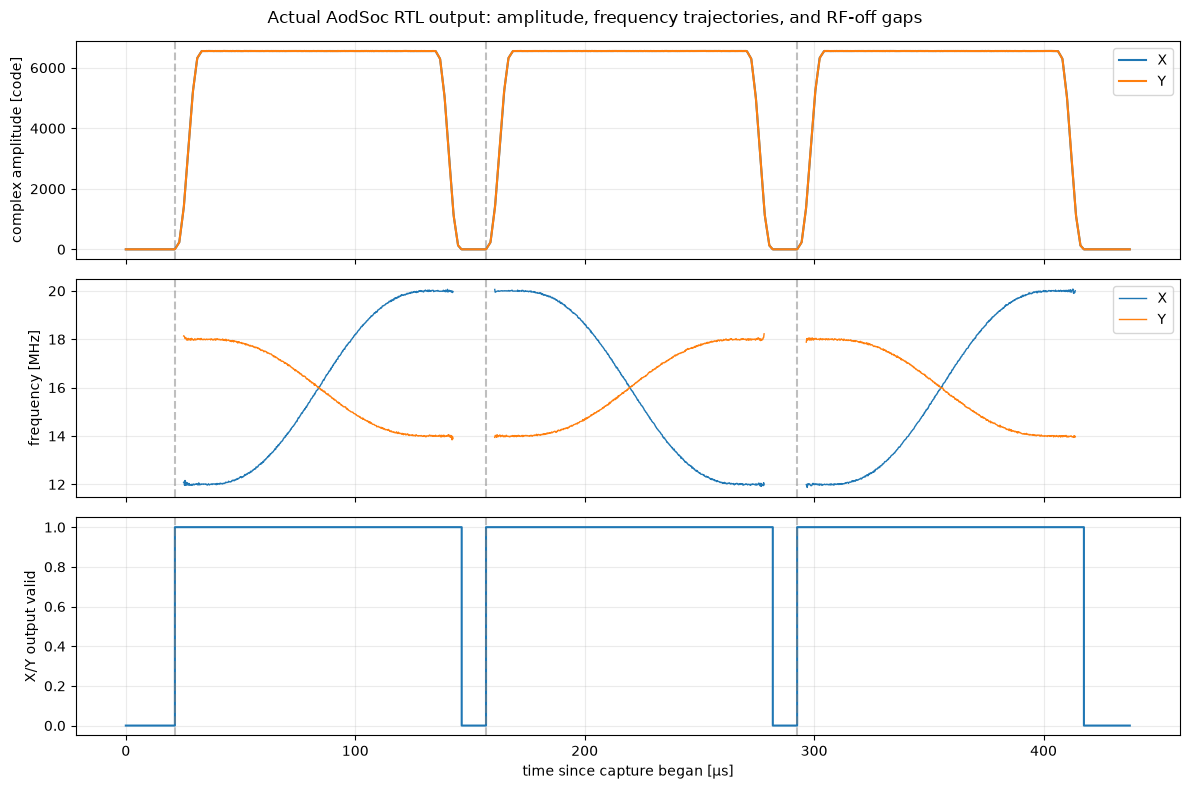

PASS: exact start times, paired X/Y validity, zero off intervals, and no AOD diagnostics.


In [8]:
def verify_capture(cap, expected_starts):
    assert np.array_equal(cap.valid[:, 0], cap.valid[:, 1]), "X/Y starts differ"
    onsets = np.flatnonzero(np.diff(cap.valid[:, 0].astype(int), prepend=0) == 1)
    assert np.array_equal(cap.times[onsets], expected_starts), "scheduled timestamps differ from RTL output"
    assert np.all(cap.iq[~cap.valid] == 0), "RF-off intervals must be zero"
    assert len(onsets) == N
    return onsets

onsets = verify_capture(capture, starts)
fs = mapping.manifest["dsp_hz"]
us = np.arange(len(capture.iq)) / fs * 1e6
signal = capture.complex
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for axis, name in enumerate(("X", "Y")):
    axes[0].plot(us[::40], np.abs(signal[::40, axis]), label=name)
    good = (capture.valid[1:, axis] & capture.valid[:-1, axis]
            & (np.abs(signal[1:, axis]) > np.abs(signal[:, axis]).max() * 0.2)
            & (np.abs(signal[:-1, axis]) > np.abs(signal[:, axis]).max() * 0.2))
    frequency = np.angle(signal[1:, axis] * np.conj(signal[:-1, axis])) * fs / (2 * np.pi)
    frequency[~good] = np.nan
    axes[1].plot(us[1::80], frequency[::80] / 1e6, label=name, linewidth=1)
axes[0].set_ylabel("complex amplitude [code]")
axes[1].set_ylabel("frequency [MHz]")
axes[2].step(us[::40], capture.valid[::40, 0].astype(int), where="post")
axes[2].set_ylabel("X/Y output valid")
axes[2].set_xlabel("time since capture began [µs]")
for ax in axes:
    for t in (starts - capture.t0) / fs * 1e6:
        ax.axvline(t, color="grey", linestyle="--", alpha=0.5)
    ax.grid(alpha=0.25)
axes[0].legend(); axes[1].legend()
fig.suptitle("Actual AodSoc RTL output: amplitude, frequency trajectories, and RF-off gaps")
fig.tight_layout()
plt.show()
print("PASS: exact start times, paired X/Y validity, zero off intervals, and no AOD diagnostics.")

## 8. Rerun with new parameters, reusing firmware and coefficients

No recompilation or profile upload occurs here. We change only the named initial
phase parameter to one quarter turn and run again. The same checks apply. Shared
time continues across shots, so absolute timestamps increase.

In [9]:
session.parameters(**{**parameters, "phase": mapping.phase(0.25)})
second_handle = driver.sim.capture_arm(clocks)
session.start()
session.wait_done(timeout=120)
second = driver.sim.capture_get(second_handle)
second_starts = np.asarray(session.result("starts"), dtype=np.int64) & 0xffffffff
assert session.diagnostics() == 0
session.stop()
verify_capture(second, second_starts)
assert second_starts[0] > starts[-1]
# Compare the first movement at equal offsets from its independently measured start.
a = np.flatnonzero(capture.times == starts[0])[0]
b = np.flatnonzero(second.times == second_starts[0])[0]
assert not np.array_equal(capture.iq[a:a+30000], second.iq[b:b+30000]), "phase parameter had no effect"
print("Second run starts:", second_starts)
print("PASS: parameter-only rerun, changed phase waveform, preserved tables, monotonic shared time.")

Second run starts: [766014 820266 874518]
PASS: parameter-only rerun, changed phase waveform, preserved tables, monotonic shared time.


## 9. Shut down the simulation

This closes the local simulation process. If an earlier cell failed, run this
cell explicitly before restarting. The AOD board backend/RFDC design is separate;
this notebook requires no board address, bitstream download, Vivado or optical setup.

In [10]:
simulator.stop(driver)
print("AOD simulation stopped.")

AOD simulation stopped.
